<img src="https://storage.googleapis.com/kaggle-datasets-images/681625/1196732/a1d8dfe666ca94f660058a2f56a5639d/dataset-cover.png?t=2020-05-29-09-01-54">

# 🗾 Aerial Image for Semantic Segmentation

# Getting started
## Installing packages

In [1]:
#!pip install tensorflow[and-cuda]==2.14
#!pip install image-classifiers
#!pip install gdown
#pip install PyMuPDF

from IPython.display import clear_output
clear_output(wait=False)

In [2]:
!wget -O ./kaggle/working/PlotNeuralNet.zip https://github.com/aletbm/Aerial_Image_Segmentation/raw/refs/heads/main/PlotNeuralNet.zip
!unzip -o ./kaggle/working/PlotNeuralNet.zip -d ./kaggle/working/
clear_output(wait=False)

## Importing packages

In [3]:
import sys
from pathlib import Path

sys.path.append(str(Path.cwd().parent))

import numpy as np
import pandas as pd
import os
import random
from tqdm.auto import tqdm

import cv2
from PIL import ImageColor

import matplotlib.pyplot as plt
import matplotlib.patches as mpatches

import tensorflow as tf
from tensorflow.image import (resize_with_pad,
                              resize,
                              crop_to_bounding_box,)

import kaggle
import kagglehub

import config as cfg

plt.style.use("dark_background")

2026-09-14 14:26:05.165933: I tensorflow/core/util/port.cc:111] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
2026-09-14 14:26:08.123806: E tensorflow/compiler/xla/stream_executor/cuda/cuda_dnn.cc:9342] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
2026-09-14 14:26:08.123844: E tensorflow/compiler/xla/stream_executor/cuda/cuda_fft.cc:609] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
2026-09-14 14:26:08.123874: E tensorflow/compiler/xla/stream_executor/cuda/cuda_blas.cc:1518] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered
2026-09-14 14:26:08.687924: I tensorflow/core/platform/cpu_feature_g

## Looking for available GPUs and what version of Tensorflow we are working on

In [4]:
device_name = tf.test.gpu_device_name()
if "GPU" not in device_name:
    print("GPU device not found")
print(f"Found GPU at: {format(device_name)}")
print(f"Num GPUs Available: {len(tf.config.list_physical_devices('GPU'))}")
print(f"Tensorflow version: {tf.__version__}")

Found GPU at: /device:GPU:0
Num GPUs Available: 1
Tensorflow version: 2.14.0


2026-09-14 14:26:18.366409: I tensorflow/compiler/xla/stream_executor/cuda/cuda_gpu_executor.cc:880] could not open file to read NUMA node: /sys/bus/pci/devices/0000:01:00.0/numa_node
Your kernel may have been built without NUMA support.
2026-09-14 14:26:19.340621: I tensorflow/compiler/xla/stream_executor/cuda/cuda_gpu_executor.cc:880] could not open file to read NUMA node: /sys/bus/pci/devices/0000:01:00.0/numa_node
Your kernel may have been built without NUMA support.
2026-09-14 14:26:19.340703: I tensorflow/compiler/xla/stream_executor/cuda/cuda_gpu_executor.cc:880] could not open file to read NUMA node: /sys/bus/pci/devices/0000:01:00.0/numa_node
Your kernel may have been built without NUMA support.
2026-09-14 14:26:19.538777: I tensorflow/compiler/xla/stream_executor/cuda/cuda_gpu_executor.cc:880] could not open file to read NUMA node: /sys/bus/pci/devices/0000:01:00.0/numa_node
Your kernel may have been built without NUMA support.
2026-09-14 14:26:19.538858: I tensorflow/compile

## Setting for reproducibility

In [5]:
tf.random.set_seed(cfg.SEED)
np.random.seed(cfg.SEED)
os.environ['PYTHONHASHSEED'] = str(cfg.SEED)
random.seed(cfg.SEED)

## Gathering and defining file paths

In [6]:
kaggle.api.authenticate()

In [7]:
kagglehub.dataset_download("aletbm/global-land-cover-mapping-openearthmap", output_dir=cfg.SOURCE_PATH / "global-land-cover-mapping-openearthmap/")
kagglehub.dataset_download("humansintheloop/semantic-segmentation-of-aerial-imagery", output_dir=cfg.SOURCE_PATH / "semantic-segmentation-of-aerial-imagery/")
kagglehub.dataset_download("aletbm/swiss-drone-and-okutama-drone-datasets", output_dir=cfg.SOURCE_PATH / "swiss-drone-and-okutama-drone-datasets/")
kagglehub.dataset_download("aletbm/urban-segmentation-isprs", output_dir=cfg.SOURCE_PATH / "urban-segmentation-isprs/")

PosixPath('/home/aletbm/proyectos/final/kaggle/input/urban-segmentation-isprs')

In [8]:
img_paths = [#cfg.SOURCE_PATH / "modified-uavid-dataset/modified_uavid_dataset/train_data/Images",
             #cfg.SOURCE_PATH / "modified-uavid-dataset/modified_uavid_dataset/val_data/Images",
             #cfg.SOURCE_PATH / "semantic-segmentation-drone-dataset/classes_dataset/classes_dataset/original_images",
             cfg.SOURCE_PATH / "semantic-segmentation-of-aerial-imagery/Semantic segmentation dataset/Tile 1/images",
             cfg.SOURCE_PATH / "semantic-segmentation-of-aerial-imagery/Semantic segmentation dataset/Tile 2/images",
             cfg.SOURCE_PATH / "semantic-segmentation-of-aerial-imagery/Semantic segmentation dataset/Tile 3/images",
             cfg.SOURCE_PATH / "semantic-segmentation-of-aerial-imagery/Semantic segmentation dataset/Tile 4/images",
             cfg.SOURCE_PATH / "semantic-segmentation-of-aerial-imagery/Semantic segmentation dataset/Tile 5/images",
             cfg.SOURCE_PATH / "semantic-segmentation-of-aerial-imagery/Semantic segmentation dataset/Tile 6/images",
             cfg.SOURCE_PATH / "semantic-segmentation-of-aerial-imagery/Semantic segmentation dataset/Tile 7/images",
             cfg.SOURCE_PATH / "semantic-segmentation-of-aerial-imagery/Semantic segmentation dataset/Tile 8/images",
             #cfg.SOURCE_PATH / "satellite-image-and-mask/train_image",
             #cfg.SOURCE_PATH / "gaofen-satellite-images-five-billion-pixels/Image__8bit_NirRGB",
             cfg.SOURCE_PATH / "urban-segmentation-isprs/Potsdam/Images",
             cfg.SOURCE_PATH / "urban-segmentation-isprs/Vaihingen/Images",
             cfg.SOURCE_PATH / "swiss-drone-and-okutama-drone-datasets/images/train",
             cfg.SOURCE_PATH / "swiss-drone-and-okutama-drone-datasets/images/test",
             cfg.SOURCE_PATH / "swiss-drone-and-okutama-drone-datasets/images/val",
             cfg.SOURCE_PATH / "global-land-cover-mapping-openearthmap/images/train",
             cfg.SOURCE_PATH / "global-land-cover-mapping-openearthmap/images/val"
            ]

msk_paths = [#cfg.SOURCE_PATH / "modified-uavid-dataset/modified_uavid_dataset/train_data/Labels",
             #cfg.SOURCE_PATH / "modified-uavid-dataset/modified_uavid_dataset/val_data/Labels",
             #cfg.SOURCE_PATH / "semantic-segmentation-drone-dataset/classes_dataset/classes_dataset/label_images_semantic",
             cfg.SOURCE_PATH / "semantic-segmentation-of-aerial-imagery/Semantic segmentation dataset/Tile 1/masks",
             cfg.SOURCE_PATH / "semantic-segmentation-of-aerial-imagery/Semantic segmentation dataset/Tile 2/masks",
             cfg.SOURCE_PATH / "semantic-segmentation-of-aerial-imagery/Semantic segmentation dataset/Tile 3/masks",
             cfg.SOURCE_PATH / "semantic-segmentation-of-aerial-imagery/Semantic segmentation dataset/Tile 4/masks",
             cfg.SOURCE_PATH / "semantic-segmentation-of-aerial-imagery/Semantic segmentation dataset/Tile 5/masks",
             cfg.SOURCE_PATH / "semantic-segmentation-of-aerial-imagery/Semantic segmentation dataset/Tile 6/masks",
             cfg.SOURCE_PATH / "semantic-segmentation-of-aerial-imagery/Semantic segmentation dataset/Tile 7/masks",
             cfg.SOURCE_PATH / "semantic-segmentation-of-aerial-imagery/Semantic segmentation dataset/Tile 8/masks",
             #cfg.SOURCE_PATH / "satellite-image-and-mask/train_mask",
             #cfg.SOURCE_PATH / "gaofen-satellite-images-five-billion-pixels/Annotation__color",
             cfg.SOURCE_PATH / "urban-segmentation-isprs/Potsdam/Labels",
             cfg.SOURCE_PATH / "urban-segmentation-isprs/Vaihingen/Labels",
             cfg.SOURCE_PATH / "swiss-drone-and-okutama-drone-datasets/ground_truth/train",
             cfg.SOURCE_PATH / "swiss-drone-and-okutama-drone-datasets/ground_truth/test",
             cfg.SOURCE_PATH / "swiss-drone-and-okutama-drone-datasets/ground_truth/val",
             cfg.SOURCE_PATH / "global-land-cover-mapping-openearthmap/label/train",
             cfg.SOURCE_PATH / "global-land-cover-mapping-openearthmap/label/val"
            ]

dt_abb = [#"MUD", "MUD",
          #"SSDD",
          "SSAI", "SSAI", "SSAI", "SSAI", "SSAI", "SSAI", "SSAI", "SSAI",
          #"SIM",
          #"FBP",
          "ISPRS", "ISPRS",
          "SO", "SO", "SO",
          "OEM", "OEM"
         ]

### Creating a CSV file to join image and mask file paths

In [9]:
if not os.path.exists(cfg.DST_PATH / "df_files.csv"):
    df_files = pd.DataFrame()
    imgs, msks = [], []
    for i, m, a in zip(img_paths, msk_paths, dt_abb):
        img_list = os.listdir(i)
        msk_list = os.listdir(m)
        img_list.sort()
        msk_list.sort()
        df_aux = pd.DataFrame(data={"filename_image": img_list, "filename_mask": msk_list})
        df_aux["filename_image"] = df_aux["filename_image"].apply(lambda x: i + '/' + x)
        df_aux["filename_mask"] = df_aux["filename_mask"].apply(lambda x: m + '/' + x)
        df_aux["dataset_abb"] = a
        df_files = pd.concat([df_files, df_aux], ignore_index=True)
    df_files.to_csv(cfg.DST_PATH / "df_files.csv", index=False)
else:
    df_files = pd.read_csv(cfg.DST_PATH / "df_files.csv")

df_files.head()

,filename_image,filename_mask,dataset_abb
0,../../kaggle/input/semantic-segmentation-of-ae...,../../kaggle/input/semantic-segmentation-of-ae...,SSAI
1,../../kaggle/input/semantic-segmentation-of-ae...,../../kaggle/input/semantic-segmentation-of-ae...,SSAI
2,../../kaggle/input/semantic-segmentation-of-ae...,../../kaggle/input/semantic-segmentation-of-ae...,SSAI
3,../../kaggle/input/semantic-segmentation-of-ae...,../../kaggle/input/semantic-segmentation-of-ae...,SSAI
4,../../kaggle/input/semantic-segmentation-of-ae...,../../kaggle/input/semantic-segmentation-of-ae...,SSAI


# Exploratory and data analysis (EDA)

## Defining useful functions

### Functions for loading images and masks

In [ ]:
def load_img(filename):
    image = tf.convert_to_tensor(cv2.imread(filename)[..., ::-1])
    return image

def get_data(df, dataset=None):
    if dataset is None:
        num_images = len(df)
        random_idx = random.randint(0, num_images - 1)
        filename_img, filename_mask, dt_abb = df.loc[random_idx]
    else:
        df_aux = df[df["dataset_abb"] == dataset]
        num_images = len(df_aux)
        random_idx = random.randint(0, num_images - 1)
        filename_img, filename_mask, dt_abb = df_aux.iloc[random_idx]

    image = load_img(filename_img)
    mask = load_img(filename_mask)
    return image, mask, dt_abb

### Functions to normalize mask colors

In [11]:
def norm_colors(mask, colors, colors_conv):
    colors = tf.cast(colors, dtype=tf.uint8)
    colors_conv = tf.cast(colors_conv, dtype=tf.uint8)
    n_colors = tf.size(colors)//3
    boolean_all = tf.TensorArray(dtype=tf.bool, size=n_colors)

    for i in tf.range(n_colors):
        x, y = colors[i], colors_conv[i]
        boolean_mask = tf.reduce_all(tf.equal(mask, x), axis=-1)
        boolean_all = boolean_all.write(i, boolean_mask)
        r, g, b = y[0], y[1], y[2]
        R = tf.where(boolean_mask, r, mask[..., 0])
        G = tf.where(boolean_mask, g, mask[..., 1])
        B = tf.where(boolean_mask, b, mask[..., 2])
        mask = tf.stack([R, G, B], axis=-1)

    boolean_all = tf.reduce_any(boolean_all.stack(), axis=0)
    unlabeled = tf.constant((0, 0, 0), dtype=tf.uint8)
    R = tf.where(boolean_all, mask[..., 0], unlabeled[0])
    G = tf.where(boolean_all, mask[..., 1], unlabeled[1])
    B = tf.where(boolean_all, mask[..., 2], unlabeled[2])
    mask = tf.stack([R, G, B], axis=-1)
    return mask

### Functions for resizing images and masks

In [12]:
def resize_image(img=None, major_size=None, padding=True):
    if padding:
        image = resize_with_pad(img, method="nearest", target_height=major_size, target_width=major_size)
    else:
        img_shape = tf.shape(img)[0:2]
        ar = img_shape[1]/img_shape[0] #W/H
        image = resize(img, method="nearest", size=(major_size, major_size*ar) if img_shape[0] > img_shape[1] else (major_size/ar, major_size))
    return image

### Functions for plotting images and masks

In [13]:
def get_patches(mask, list_colors, list_classes):
    colors, _ = tf.raw_ops.UniqueV2(x=tf.reshape(mask, (-1, 3)), axis=[0])
    colors = tf.cast(colors, dtype=tf.int32)
    patches = []
    color_idx = tf.expand_dims(tf.zeros(tf.shape(colors)[0], dtype=tf.bool), axis=-1)
    for i, color in enumerate(list_colors):
        color_idx = tf.concat([color_idx, tf.expand_dims(tf.reduce_all(colors == color, 1), axis=-1)], axis=-1)
    color_idx = tf.cast(tf.argmax(color_idx, axis=1), dtype=tf.int32).numpy()

    color_idx = color_idx[color_idx > 0]-1

    for idx_classes in color_idx:
        color = tuple(list_colors[idx_classes].numpy()/255)
        obj = list_classes[idx_classes]
        patches.append(mpatches.Patch(color=color, label=obj))
    return patches

def subplot(image, num_row, num_cols, idx, title, fontsize=8, patches=None, cmap=None, vmin=None, vmax=None):
    plt.subplot(num_row, num_cols, idx)
    plt.imshow(image, cmap=cmap, vmin=vmin, vmax=vmax, interpolation='none')
    plt.tick_params(bottom=False, top=False, left=False, right=False, labelbottom=False, labelleft=False)
    plt.title(title, fontsize=fontsize)
    if patches:
        plt.legend(handles=patches, fontsize=5.3, facecolor='white', labelcolor='black')
    return

def plot_sample(img, mask, df_colors, num_img=1, num_cols=2, ind=0, norm=False, color_correction=False, df_colors_conv=None, size_img=None):
    color_rgb = tf.constant(df_colors["Color_RGB"].tolist())
    classes = df_colors["Classes"].tolist()

    ind += 1
    subplot(image=img, num_row=num_img, num_cols=num_cols, idx=ind, title="Aerial image")

    ind += 1
    patches = get_patches(mask, color_rgb, classes)
    subplot(image=mask, num_row=num_img, num_cols=num_cols, idx=ind, title="Original mask", patches=patches)

    if norm == True or color_correction == True:
        color_conv = tf.constant(df_colors["Conversion"].tolist())
        baseline_classes = df_colors_conv.get_classes()
        baseline_color_rgb = tf.constant(df_colors_conv.get_colors())

    if norm == True:
        ind += 1
        mask_norm = norm_colors(mask, color_rgb, color_conv)
        patches = get_patches(mask_norm, baseline_color_rgb, baseline_classes)
        subplot(image=mask_norm, num_row=num_img, num_cols=num_cols, idx=ind, title="Re-Colorized mask", patches=patches)

    if color_correction == True:
        ind += 1
        mask_cor = mask_color_correction(mask, color_rgb)
        mask_norm = norm_colors(mask_cor, color_rgb, color_conv)
        patches = get_patches(mask_norm, baseline_color_rgb, baseline_classes)
        subplot(image=mask_norm, num_row=num_img, num_cols=num_cols, idx=ind, title="Re-Colorized mask with pixel color correction", patches=patches)
    return

def plot_samples(dataset, df_colors, df_files, num_img=1, w_disp=8, h_disp=5, norm=False, color_correction=False, df_colors_conv=None, size_img=None):
    num_cols = 2
    if norm == True:
        num_cols += 1
    if color_correction == True:
        num_cols += 1

    plt.subplots(num_img, num_cols, figsize=(w_disp, h_disp))

    for i in range(num_img):
        df_colors_ = df_colors.copy()
        ind = i*num_cols
        img, mask, abb = get_data(df_files, dataset=dataset)

        if size_img is not None:
            img = resize_image(img, size_img)
            mask = resize_image(mask, size_img)

        if abb == "SO" or abb == "OEM":
            color_rgb = tf.constant(df_colors_["Color_RGB"].tolist())
            re_color = tf.constant(df_colors_["Re-Color"].tolist())
            mask = norm_colors(mask, color_rgb, re_color)
            df_colors_["Color_RGB"] = df_colors_["Re-Color"]

        if abb == "ISPRS" or abb == "FBP":
            if abb == "FBP":
                img = img[..., ::-1]
            mask = mask[..., ::-1]

        plot_sample(img, mask, df_colors_, num_img, num_cols, ind, norm, color_correction, df_colors_conv)
    return

### Class for handling labels

In [14]:
class myLabels():
    def __init__(self):
        self.classes = {"Building":[60, 16, 152],
                        "Environment":[132, 41, 246],
                        "Road":[110, 193, 228],
                        "Unlabeled":[0, 0, 0]}

    def get_color(self, cat):
        return self.classes[cat]

    def get_colors(self):
        return list(self.classes.values())

    def get_class(self, clr):
        for class_, color in self.classes.items():
            if clr == color:
                break
        return class_

    def get_classes(self):
        return list(self.classes.keys())

Labels = myLabels()
num_classes = len(Labels.get_classes())

## Working on each dataset
### Dataset: Semantic segmentation of aerial image

In [15]:
print(f'Number of images in the dataset: {df_files[df_files["dataset_abb"] == "SSAI"]["dataset_abb"].count()}')

Number of images in the dataset: 72


#### Colors and classes in the masks

In [16]:
seg_classes = ["Building",
               "Land",
               "Road",
               "Vegetation",
               "Water",
               "Unlabeled",
               "Unlabeled",
              ]

color_hex = ["#3C1098",
             "#8429F6",
             "#6EC1E4",
             "#FEDD3A",
             "#E2A929",
             "#000000",
             "#9B9B9B",
            ]

color_rgb = [np.array(ImageColor.getcolor(hex_, "RGB")) for hex_ in color_hex]
SSAI_colors = pd.DataFrame(data={"Classes": seg_classes, "Color_HEX": color_hex, "Color_RGB": color_rgb})
SSAI_colors

,Classes,Color_HEX,Color_RGB
0,Building,#3C1098,"[60, 16, 152]"
1,Land,#8429F6,"[132, 41, 246]"
2,Road,#6EC1E4,"[110, 193, 228]"
3,Vegetation,#FEDD3A,"[254, 221, 58]"
4,Water,#E2A929,"[226, 169, 41]"
5,Unlabeled,#000000,"[0, 0, 0]"
6,Unlabeled,#9B9B9B,"[155, 155, 155]"


2026-09-14 14:26:25.312496: I tensorflow/compiler/xla/stream_executor/cuda/cuda_gpu_executor.cc:880] could not open file to read NUMA node: /sys/bus/pci/devices/0000:01:00.0/numa_node
Your kernel may have been built without NUMA support.
2026-09-14 14:26:25.312646: I tensorflow/compiler/xla/stream_executor/cuda/cuda_gpu_executor.cc:880] could not open file to read NUMA node: /sys/bus/pci/devices/0000:01:00.0/numa_node
Your kernel may have been built without NUMA support.
2026-09-14 14:26:25.312733: I tensorflow/compiler/xla/stream_executor/cuda/cuda_gpu_executor.cc:880] could not open file to read NUMA node: /sys/bus/pci/devices/0000:01:00.0/numa_node
Your kernel may have been built without NUMA support.
2026-09-14 14:26:25.312922: I tensorflow/compiler/xla/stream_executor/cuda/cuda_gpu_executor.cc:880] could not open file to read NUMA node: /sys/bus/pci/devices/0000:01:00.0/numa_node
Your kernel may have been built without NUMA support.
2026-09-14 14:26:25.312935: I tensorflow/core/co

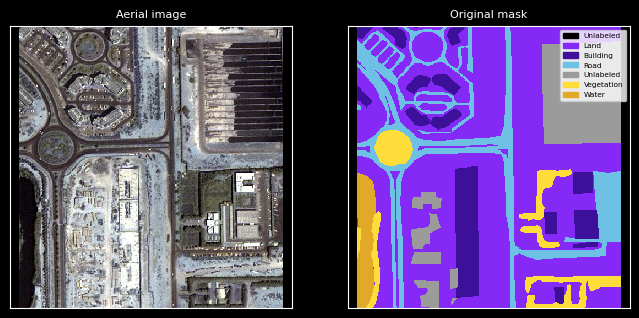

In [17]:
plot_samples("SSAI", SSAI_colors, df_files, size_img=cfg.SIZE_TO_PLOT)

#### Conversion of colors

In [18]:
SSAI_colors["Conversion"] = [Labels.get_color("Building"),
                             Labels.get_color("Environment"),
                             Labels.get_color("Road"),
                             Labels.get_color("Environment"),
                             Labels.get_color("Environment"),
                             Labels.get_color("Unlabeled"),
                             Labels.get_color("Unlabeled")]

SSAI_colors = SSAI_colors.iloc[:-1]
SSAI_colors

,Classes,Color_HEX,Color_RGB,Conversion
0,Building,#3C1098,"[60, 16, 152]","[60, 16, 152]"
1,Land,#8429F6,"[132, 41, 246]","[132, 41, 246]"
2,Road,#6EC1E4,"[110, 193, 228]","[110, 193, 228]"
3,Vegetation,#FEDD3A,"[254, 221, 58]","[132, 41, 246]"
4,Water,#E2A929,"[226, 169, 41]","[132, 41, 246]"
5,Unlabeled,#000000,"[0, 0, 0]","[0, 0, 0]"


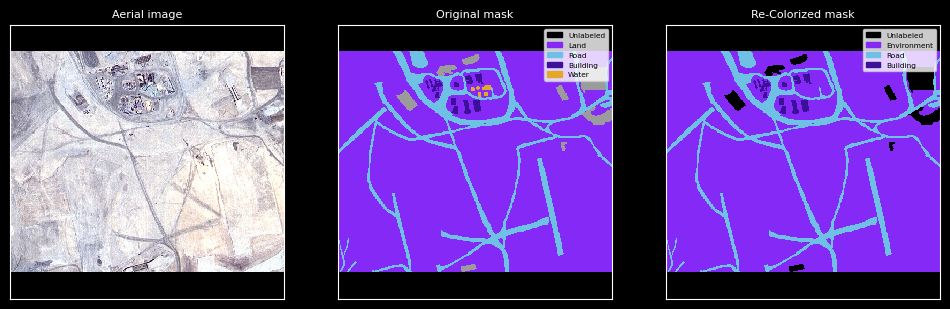

In [19]:
plot_samples("SSAI", SSAI_colors, df_files, num_img=1, norm=True, df_colors_conv=Labels, h_disp=5, w_disp=12, size_img=cfg.SIZE_TO_PLOT)

### Correcting the color of mask pixels

While mask re-colorization process we wrongly introduce black halos due to pixel color weakness in frontier between two different classes when we resize image. We must correct this problem since this introduce a missclassification of pixels.

But, how to resolve this problem? Let us see RGB domain in a 3 dimensional-space:

<img src="https://i.ibb.co/SwrPMPF/RGB-3d.png" width=200>

The RGB domain can be represented by a cube, where each point inside cube represent a color, each point have 3 components that determine its position.
The distance between two points inside cube can be calculated with Euclidean distance equation for two points in 3 dimensional-space:

<img src="https://i.ibb.co/QdDQ40C/589px-Euclidean-distance-3d-2-cropped.png" width=300>

The distance is:

$d(p, q)=\sqrt{|p_1-q_1|^2 + |p_2-q_2|^2 + |p_3-q_3|^2} \quad\text{where} \quad p=(p_1,p_2,p_3),q=(q_1,q_2,q_3) \quad\text{any two points}$

This way we can approximate the weak colors to most near color class.

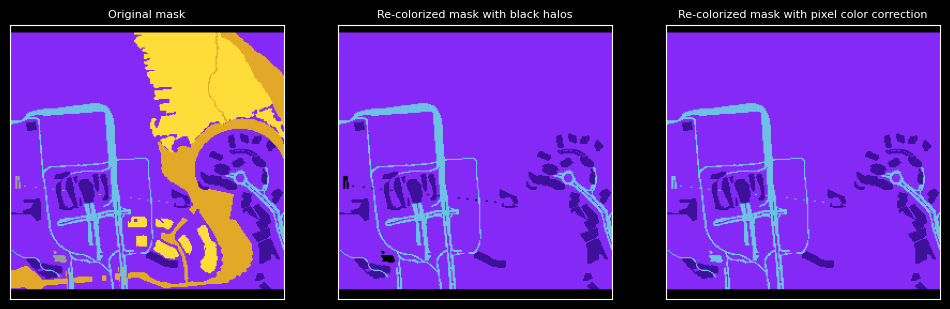

In [20]:
def euclidean_distance(mask, color):
    sum_ = tf.cast(tf.reduce_sum(tf.math.pow(mask-color, 2), axis=2), dtype=tf.float32)
    return tf.math.sqrt(sum_)

def mask_color_correction(mask, colors):
    n_colors = tf.size(colors)//3
    mask_ = tf.cast(mask, dtype=tf.int32)
    mask_cor = tf.TensorArray(dtype=tf.float32, size=n_colors)

    for i in tf.range(n_colors):
        mask_cor = mask_cor.write(i, euclidean_distance(mask_, colors[i]))
    mask_cor = tf.transpose(mask_cor.stack(), perm=[1, 2, 0])

    mask_cor = tf.cast(tf.argmin(mask_cor, axis=2), dtype=tf.int32)
    mask_bool = tf.cast(tf.tile(tf.expand_dims(tf.clip_by_value(tf.reduce_max(mask, 2), 0, 1), -1), [1, 1, 3]), dtype=tf.uint8)
    mask_cor = tf.cast(tf.gather(colors, mask_cor), dtype=tf.uint8)
    return mask_bool * mask_cor

plt.subplots(1, 3, figsize=(12, 5))

img = load_img(cfg.SOURCE_PATH / "semantic-segmentation-of-aerial-imagery/Semantic segmentation dataset/Tile 5/images/image_part_007.jpg")
mask = load_img(cfg.SOURCE_PATH / "semantic-segmentation-of-aerial-imagery/Semantic segmentation dataset/Tile 5/masks/image_part_007.png")
colors_rgb = tf.constant(SSAI_colors["Color_RGB"].to_list())
colors_conv = tf.constant(SSAI_colors["Conversion"].to_list())

img = resize_image(img, cfg.SIZE_IMG)
mask = resize_image(mask, cfg.SIZE_IMG)

plt.subplot(1, 3, 1)
plt.imshow(mask)
plt.tick_params(bottom=False, top=False, left=False, right=False, labelbottom=False, labelleft=False)
plt.title("Original mask", fontsize=8)

plt.subplot(1, 3, 2)
plt.imshow(norm_colors(mask, colors_rgb, colors_conv))
plt.tick_params(bottom=False, top=False, left=False, right=False, labelbottom=False, labelleft=False)
plt.title("Re-colorized mask with black halos", fontsize=8)

plt.subplot(1, 3, 3)
mask_cor = mask_color_correction(mask, colors_rgb)
plt.imshow(norm_colors(mask_cor, colors_rgb, colors_conv))
plt.tick_params(bottom=False, top=False, left=False, right=False, labelbottom=False, labelleft=False)
plt.title("Re-colorized mask with pixel color correction", fontsize=8);

This effect appreciate more in the next dataset.

### Dataset: Urban Segmentation - ISPRS

In [21]:
print(f'Number of images in the dataset: {df_files[df_files["dataset_abb"] == "ISPRS"]["dataset_abb"].count()}')

Number of images in the dataset: 71


#### Colors and classes in the masks

In [22]:
seg_classes = ["Impervious surfaces",
               "Building",
               "Low vegetation",
               "Tree",
               "Car",
               "Clutter/background",
               "Background",]

color_bgr = [(255, 255, 255),
             (0, 0, 255),
             (0, 255, 255),
             (0, 255, 0),
             (255, 255, 0),
             (255, 0, 0),
             (0, 0, 0),]

color_bgr = np.array([np.array(color) for color in color_bgr])

color_rgb = np.stack([color_bgr[..., 2], color_bgr[..., 1], color_bgr[..., 0]], axis=-1)
color_rgb = [np.array(color) for color in color_rgb]

ISPRS_colors = pd.DataFrame(data={"Classes": seg_classes, "Color_RGB": color_rgb})
ISPRS_colors

,Classes,Color_RGB
0,Impervious surfaces,"[255, 255, 255]"
1,Building,"[255, 0, 0]"
2,Low vegetation,"[255, 255, 0]"
3,Tree,"[0, 255, 0]"
4,Car,"[0, 255, 255]"
5,Clutter/background,"[0, 0, 255]"
6,Background,"[0, 0, 0]"


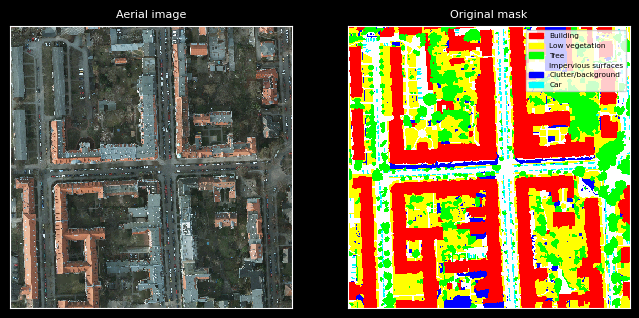

In [23]:
plot_samples("ISPRS", ISPRS_colors, df_files, size_img=cfg.SIZE_TO_PLOT)

#### Conversion of colors
##### Conversion table

<table>
    <tr><th>ISPRS categories</th><th>Baseline</th></tr>
    <tr><td>Impervious surfaces</td><td>Road</td></tr>
    <tr><td>Building</td><td>Building</td></tr>
    <tr><td>Low vegetation</td><td>Environment</td></tr>
    <tr><td>Tree</td><td>Environment</td></tr>
    <tr><td>Car</td><td>Environment</td></tr>
    <tr><td>Clutter/background</td><td>Environment</td></tr>
    <tr><td>Background</td><td>Unlabeled</td></tr>
</table>

In [24]:
ISPRS_colors["Conversion"] = [Labels.get_color("Road"),
                              Labels.get_color("Building"),
                              Labels.get_color("Environment"),
                              Labels.get_color("Environment"),
                              Labels.get_color("Environment"),
                              Labels.get_color("Environment"),
                              Labels.get_color("Unlabeled"),]

ISPRS_colors

,Classes,Color_RGB,Conversion
0,Impervious surfaces,"[255, 255, 255]","[110, 193, 228]"
1,Building,"[255, 0, 0]","[60, 16, 152]"
2,Low vegetation,"[255, 255, 0]","[132, 41, 246]"
3,Tree,"[0, 255, 0]","[132, 41, 246]"
4,Car,"[0, 255, 255]","[132, 41, 246]"
5,Clutter/background,"[0, 0, 255]","[132, 41, 246]"
6,Background,"[0, 0, 0]","[0, 0, 0]"


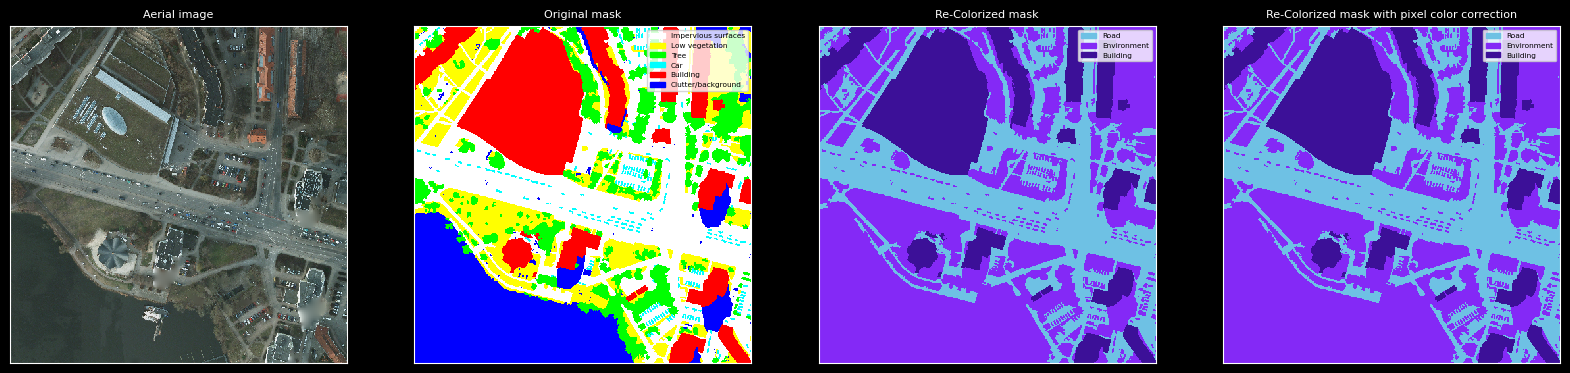

In [25]:
plot_samples("ISPRS", ISPRS_colors, df_files, w_disp=20, norm=True, color_correction=True, df_colors_conv=Labels, size_img=cfg.SIZE_TO_PLOT)

### Dataset: Swiss Drone and Okutama Drone Datasets

In [26]:
print(f'Number of images in the dataset: {df_files[df_files["dataset_abb"] == "SO"]["dataset_abb"].count()}')

Number of images in the dataset: 191


#### Colors and classes in the masks

In [27]:
seg_classes = ["People",
               "Water",
               "Wheeled vehicles",
               "Plants",
               "Train tracks",
               "Non-paved ground",
               "Paved ground",
               "Buildings",
               "Outdoor structures",
               "Background",
              ]

base = np.array([1, 1, 1])

color_rgb = [i*base for i in range(len(seg_classes))][::-1]

re_color_rgb = [[240, 255, 0],
                [0, 168, 255],
                [6, 0, 130],
                [31, 123, 22],
                [128, 0, 128],
                [189, 107, 0],
                [135, 135, 135],
                [181, 0, 0],
                [237, 237, 237],
                [0, 0, 0],
               ]

SO_colors = pd.DataFrame(data={"Classes": seg_classes, "Color_RGB": color_rgb, "Re-Color": re_color_rgb})
SO_colors

,Classes,Color_RGB,Re-Color
0,People,"[9, 9, 9]","[240, 255, 0]"
1,Water,"[8, 8, 8]","[0, 168, 255]"
2,Wheeled vehicles,"[7, 7, 7]","[6, 0, 130]"
3,Plants,"[6, 6, 6]","[31, 123, 22]"
4,Train tracks,"[5, 5, 5]","[128, 0, 128]"
5,Non-paved ground,"[4, 4, 4]","[189, 107, 0]"
6,Paved ground,"[3, 3, 3]","[135, 135, 135]"
7,Buildings,"[2, 2, 2]","[181, 0, 0]"
8,Outdoor structures,"[1, 1, 1]","[237, 237, 237]"
9,Background,"[0, 0, 0]","[0, 0, 0]"


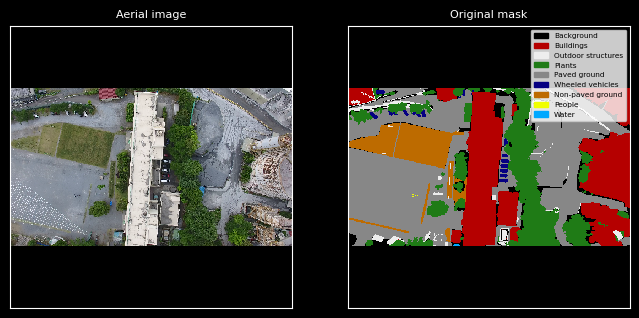

In [28]:
plot_samples("SO", SO_colors, df_files, size_img=cfg.SIZE_TO_PLOT)

#### Conversion of colors
##### Conversion table
<table>
    <tr><th>SO categories</th><th>Baseline</th></tr>
    <tr><td>People</td><td>Environment</td></tr>
    <tr><td>Water</td><td>Environment</td></tr>
    <tr><td>Wheeled vehicles</td><td>Environment</td></tr>
    <tr><td>Plants</td><td>Environment</td></tr>
    <tr><td>Train tracks</td><td>Road</td></tr>
    <tr><td>Non-paved ground</td><td>Environment</td></tr>
    <tr><td>Paved ground</td><td>Road</td></tr>
    <tr><td>Buildings</td><td>Building</td></tr>
    <tr><td>Outdoor structures</td><td>Environment</td></tr>
    <tr><td>Background</td><td>Unlabeled</td></tr>
</table>

In [29]:
SO_colors["Conversion"] = [Labels.get_color("Environment"),
                           Labels.get_color("Environment"),
                           Labels.get_color("Environment"),
                           Labels.get_color("Environment"),
                           Labels.get_color("Road"),
                           Labels.get_color("Environment"),
                           Labels.get_color("Road"),
                           Labels.get_color("Building"),
                           Labels.get_color("Environment"),
                           Labels.get_color("Unlabeled"),
                          ]

SO_colors

,Classes,Color_RGB,Re-Color,Conversion
0,People,"[9, 9, 9]","[240, 255, 0]","[132, 41, 246]"
1,Water,"[8, 8, 8]","[0, 168, 255]","[132, 41, 246]"
2,Wheeled vehicles,"[7, 7, 7]","[6, 0, 130]","[132, 41, 246]"
3,Plants,"[6, 6, 6]","[31, 123, 22]","[132, 41, 246]"
4,Train tracks,"[5, 5, 5]","[128, 0, 128]","[110, 193, 228]"
5,Non-paved ground,"[4, 4, 4]","[189, 107, 0]","[132, 41, 246]"
6,Paved ground,"[3, 3, 3]","[135, 135, 135]","[110, 193, 228]"
7,Buildings,"[2, 2, 2]","[181, 0, 0]","[60, 16, 152]"
8,Outdoor structures,"[1, 1, 1]","[237, 237, 237]","[132, 41, 246]"
9,Background,"[0, 0, 0]","[0, 0, 0]","[0, 0, 0]"


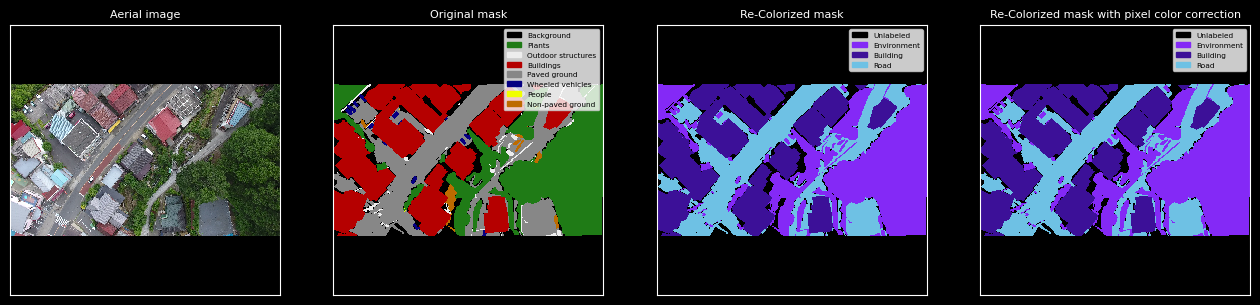

In [30]:
plot_samples("SO", SO_colors, df_files, w_disp=16, norm=True, color_correction=True, df_colors_conv=Labels, size_img=cfg.SIZE_TO_PLOT)

### Dataset: Global Land Cover Mapping - OpenEarthMap

In [31]:
print(f'Number of images in the dataset: {df_files[df_files["dataset_abb"] == "OEM"]["dataset_abb"].count()}')

Number of images in the dataset: 2687


#### Colors and classes in the masks

In [32]:
seg_classes = ["Building",
               "Agriculture land",
               "Water",
               "Tree",
               "Road",
               "Developed space",
               "Rangeland",
               "Bareland",
               "Background",
              ]

color_hex = ["#DE1F07",
             "#4BB549",
             "#0045FF",
             "#226126",
             "#FFFFFF",
             "#949494",
             "#00FF24",
             "#800000",
             "#000000",
            ]

base = np.array([1, 1, 1])
color_rgb = [i*base for i in range(len(seg_classes))][::-1]

re_color_rgb = [np.array(ImageColor.getcolor(hex_, "RGB")) for hex_ in color_hex]

OEM_colors = pd.DataFrame(data={"Classes": seg_classes, "Color_RGB": color_rgb, "Re-Color": re_color_rgb})
OEM_colors

,Classes,Color_RGB,Re-Color
0,Building,"[8, 8, 8]","[222, 31, 7]"
1,Agriculture land,"[7, 7, 7]","[75, 181, 73]"
2,Water,"[6, 6, 6]","[0, 69, 255]"
3,Tree,"[5, 5, 5]","[34, 97, 38]"
4,Road,"[4, 4, 4]","[255, 255, 255]"
5,Developed space,"[3, 3, 3]","[148, 148, 148]"
6,Rangeland,"[2, 2, 2]","[0, 255, 36]"
7,Bareland,"[1, 1, 1]","[128, 0, 0]"
8,Background,"[0, 0, 0]","[0, 0, 0]"


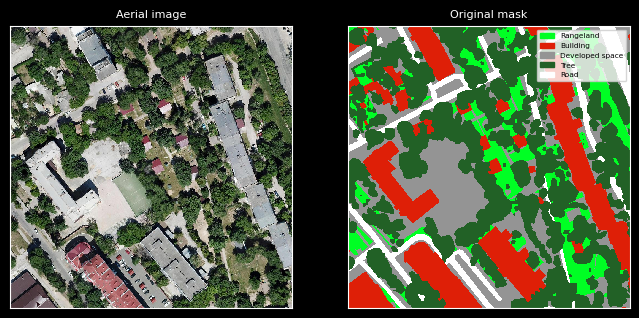

In [33]:
plot_samples("OEM", OEM_colors, df_files)

#### Conversion of colors
##### Conversion table

<table>
    <tr><th>OEM categories</th><th>Baseline</th></tr>
    <tr><td>Building</td><td>Building</td></tr>
    <tr><td>Agriculture land</td><td>Environment</td></tr>
    <tr><td>Water</td><td>Environment</td></tr>
    <tr><td>Tree</td><td>Environment</td></tr>
    <tr><td>Road</td><td>Road</td></tr>
    <tr><td>Developed space</td><td>Road</td></tr>
    <tr><td>Rangeland</td><td>Environment</td></tr>
    <tr><td>Bareland</td><td>Environment</td></tr>
    <tr><td>Background</td><td>Unlabeled</td></tr>
</table>

In [34]:
OEM_colors["Conversion"] = [Labels.get_color("Building"),
                           Labels.get_color("Environment"),
                           Labels.get_color("Environment"),
                           Labels.get_color("Environment"),
                           Labels.get_color("Road"),
                           Labels.get_color("Road"),
                           Labels.get_color("Environment"),
                           Labels.get_color("Environment"),
                           Labels.get_color("Unlabeled")]

OEM_colors

,Classes,Color_RGB,Re-Color,Conversion
0,Building,"[8, 8, 8]","[222, 31, 7]","[60, 16, 152]"
1,Agriculture land,"[7, 7, 7]","[75, 181, 73]","[132, 41, 246]"
2,Water,"[6, 6, 6]","[0, 69, 255]","[132, 41, 246]"
3,Tree,"[5, 5, 5]","[34, 97, 38]","[132, 41, 246]"
4,Road,"[4, 4, 4]","[255, 255, 255]","[110, 193, 228]"
5,Developed space,"[3, 3, 3]","[148, 148, 148]","[110, 193, 228]"
6,Rangeland,"[2, 2, 2]","[0, 255, 36]","[132, 41, 246]"
7,Bareland,"[1, 1, 1]","[128, 0, 0]","[132, 41, 246]"
8,Background,"[0, 0, 0]","[0, 0, 0]","[0, 0, 0]"


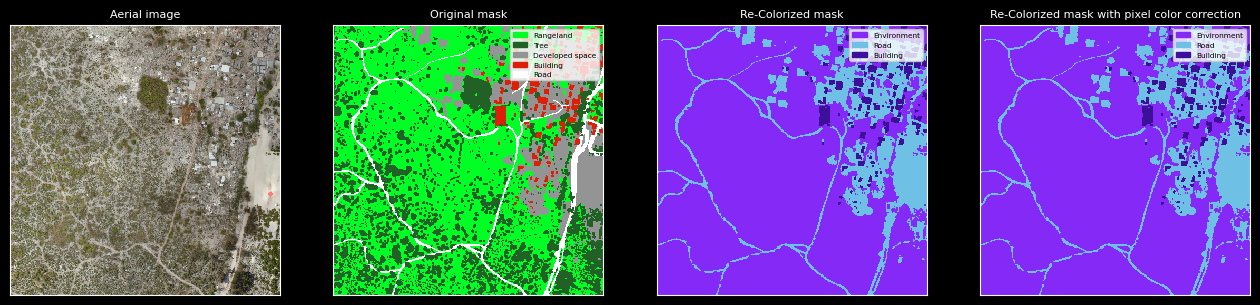

In [35]:
plot_samples("OEM", OEM_colors, df_files, w_disp=16, norm=True, color_correction=True, df_colors_conv=Labels, size_img=cfg.SIZE_TO_PLOT)

# Creating patches from big image

## Defining useful functions

In [36]:
def normalize_size(image, size_img):
    img_shape = tf.shape(image)[:2]
    min_side = tf.reduce_min(img_shape)
    max_side = tf.reduce_max(img_shape)
    ar = max_side/min_side

    if min_side != size_img:
        max_side_resize = size_img * ar
        image = resize_image(image, max_side_resize, padding=False)
    return image

def crop_image(image, size_img):
    img_shape = tf.shape(image)
    h = img_shape[0]
    w = img_shape[1]

    n_rows = tf.cast(tf.math.ceil(h/size_img), dtype=tf.int32)
    n_cols = tf.cast(tf.math.ceil(w/size_img), dtype=tf.int32)

    crops_image = tf.TensorArray(dtype=tf.uint8, size=n_rows*n_cols)

    i = 0
    for r in range(n_rows):
        h0 = h-size_img if h < size_img*(1 + r) else size_img*r
        for c in range(n_cols):
            w0 = w-size_img if w < size_img*(1 + c) else size_img*c
            crops_image = crops_image.write(i, crop_to_bounding_box(image, h0, w0, size_img, size_img))
            i += 1

    return crops_image.stack()

## Loading a example

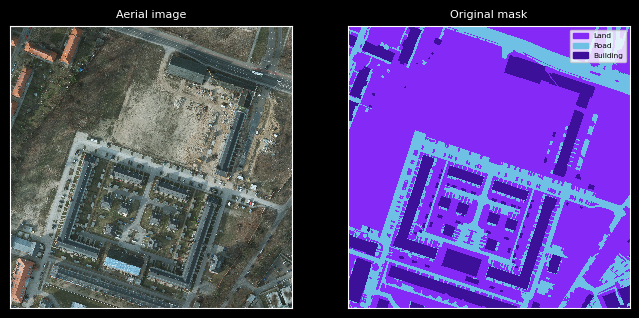

In [37]:
img = load_img(cfg.SOURCE_PATH / "urban-segmentation-isprs/Potsdam/Images/top_potsdam_2_10_RGB.tif")
msk = load_img(cfg.SOURCE_PATH / "urban-segmentation-isprs/Potsdam/Labels/top_potsdam_2_10_label.tif")[..., ::-1]

#img = load_img(cfg.SOURCE_PATH / "swiss-drone-and-okutama-drone-datasets/images/train/okutama_02_50_016.png")
#msk = load_img(cfg.SOURCE_PATH / "swiss-drone-and-okutama-drone-datasets/ground_truth/train/okutama_02_50_016.png")[..., ::-1]

#img = tf.image.rot90(img)
#msk = tf.image.rot90(msk)

color_rgb = tf.constant(ISPRS_colors["Color_RGB"].to_list(), dtype=tf.int32)
color_conv = tf.constant(ISPRS_colors["Conversion"].to_list(), dtype=tf.int32)
mask_cor = mask_color_correction(msk, color_rgb)
mask_norm = norm_colors(mask_cor, color_rgb, color_conv)

plt.subplots(1, 2, figsize=(8, 12))
plot_sample(img, mask_norm, SSAI_colors)

## Extracting and plotting patches

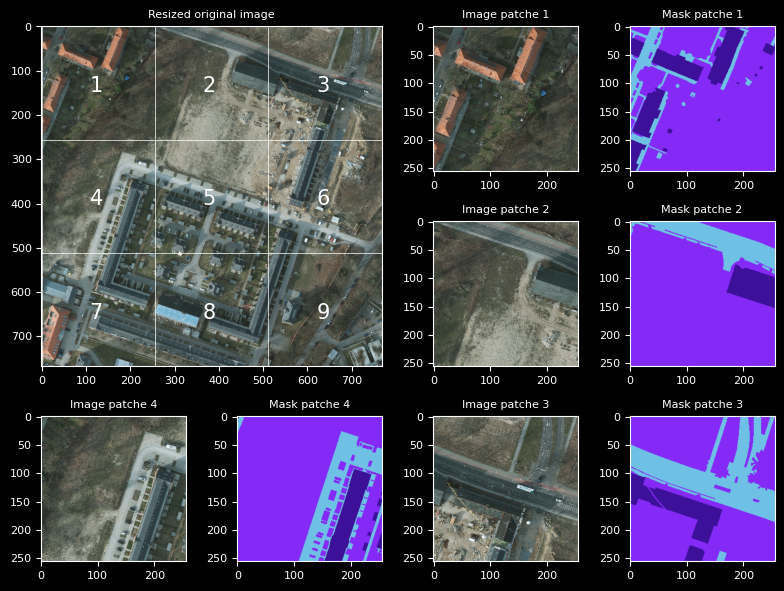

In [38]:
size_img = 256
image = normalize_size(img, 3*size_img)
mask = normalize_size(mask_norm, 3*size_img)
crops_image = crop_image(image, size_img)
crops_mask = crop_image(mask, size_img)

idx = 0
n_img = 4
fig, axs = plt.subplots(3, 4, figsize=(8, 6))
gs = axs[2, 2].get_gridspec()

for ax_ in axs[:2, :2]:
    for ax in ax_:
        ax.remove()
fig.add_subplot(gs[:2, :2])
plt.imshow(image)

h, w = tf.shape(image)[:2]
for i in range(np.ceil(w/size_img).astype(np.int32)):
    plt.axvline(x=size_img*i, lw=0.5)
for i in range(np.ceil(h/size_img).astype(np.int32)):
    plt.axhline(y=size_img*i, lw=0.5)

xv, yv = np.meshgrid(np.arange(size_img//2, h, size_img), np.arange(size_img//2, w, size_img))
xy_center = tf.reshape(tf.concat([tf.expand_dims(xv, -1), tf.expand_dims(yv, -1)], axis=2), shape=(-1, 2))
crop_number = np.arange(1, len(crops_image)+1)
for i, xy in enumerate(xy_center):
    x0 = xy[0] - 20
    y0 = xy[1] + 20
    plt.text(x0, y0, crop_number[i], fontsize=15)
plt.title("Resized original image", fontsize=8)
plt.tick_params(axis='x', which='major', labelsize=8)
plt.tick_params(axis='y', which='major', labelsize=8)

for i in range(n_img):
    idx_i, idx_m = [(3, 4), (7, 8), (11, 12), (9, 10)][i]
    plt.subplot(3, 4, idx_i)
    plt.imshow(crops_image[i])
    plt.title(f"Image patche {crop_number[i]}", fontsize=8)
    plt.tick_params(axis='x', which='major', labelsize=8)
    plt.tick_params(axis='y', which='major', labelsize=8)

    plt.subplot(3, 4, idx_m)
    plt.imshow(crops_mask[i])
    plt.title(f"Mask patche {crop_number[i]}", fontsize=8)
    plt.tick_params(axis='x', which='major', labelsize=8)
    plt.tick_params(axis='y', which='major', labelsize=8)

fig.tight_layout()

In [39]:
print(f"We extracted {len(crops_image)} {size_img}x{size_img} sub-images from a {h.numpy()}x{w.numpy()} image.")

We extracted 9 256x256 sub-images from a 768x768 image.


## Restore image from patches

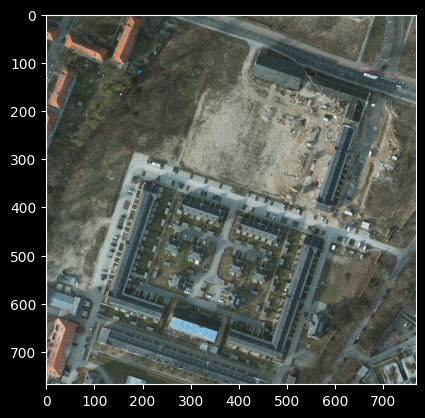

In [40]:
def restore_image(crops_image, image_shape):
    h = image_shape[0]
    w = image_shape[1]

    crop_size = crops_image[1].shape[0]

    n_rows = tf.cast(tf.math.ceil(h/crop_size), dtype=tf.int32)
    n_cols = tf.cast(tf.math.ceil(w/crop_size), dtype=tf.int32)

    rows = []
    for i in range(n_rows):
        crops = [i for i in crops_image[(i*n_cols):(i*n_cols)+n_cols]]
        restored_row = tf.concat(crops, axis=1)
        if w/crop_size < tf.cast(n_cols, dtype=tf.float64):
            crops[-1] = crops[-1][:, - (w-restored_row.shape[1]):]
        rows.append(tf.concat(crops, axis=1))

    restored_image = tf.concat(rows, axis=0)

    if restored_image.shape[0] > h:
        rows[-1] = rows[-1][(restored_image.shape[0]-h):, :]

    restored_image = tf.concat(rows, axis=0)
    return restored_image

img_shape = tf.shape(image)
restored_image = restore_image(crops_image, img_shape)
plt.imshow(restored_image);

# Joining the datasets

In [41]:
list_abb = list(set(dt_abb))
list_abb.sort()
list_abb

['ISPRS', 'OEM', 'SO', 'SSAI']

In [42]:
palettes = dict(zip(list_abb, [#FBP_colors,
                               ISPRS_colors,
                               #MUD_colors,
                               OEM_colors,
                               #SIM_colors,
                               SO_colors,
                               SSAI_colors,
                               #SSDD_colors
                              ]))
#palettes = [MUD_colors, SSDD_colors, SSAI_colors, SIM_colors, FBP_colors, ISPRS_colors, SO_colors]

## Creating a CSV file with all shuffled file paths

In [43]:
df_files_shuffled = df_files[df_files["dataset_abb"].isin(["MUD", "SSDD", "SSAI", "ISPRS", "SO", "OEM"])]
df_files_shuffled = df_files_shuffled.sample(frac=1, random_state=cfg.SEED).reset_index(drop=True)

n = len(df_files_shuffled)
train_end = int(0.75 * n)
val_end = train_end + int(0.125 * n)

df_train = df_files_shuffled.iloc[:train_end]
df_val   = df_files_shuffled.iloc[train_end:val_end]
df_test  = df_files_shuffled.iloc[val_end:]

## Creating a TFRecordDataset for containing all preprocessed images and mask

In [ ]:
def get_palettes(abb):
    df_colors = palettes[abb]
    color_rgb = df_colors["Color_RGB"].to_list()
    color_conv = df_colors["Conversion"].to_list()
    return tf.cast(color_rgb, dtype=tf.int32), tf.cast(color_conv, dtype=tf.int32)

def normalize_colors(image, mask, abb):
    if abb == "ISPRS" or abb == "FBP":
        if abb == "FBP":
            crop_image = image[..., ::-1]
        mask = mask[..., ::-1]
    color_rgb, color_conv = get_palettes(abb)
    mask_cor = mask_color_correction(mask, color_rgb)
    mask = norm_colors(mask_cor, color_rgb, color_conv)
    return tf.cast(image, dtype=tf.uint8), tf.cast(mask, dtype=tf.uint8)

def write_shard(shard_df, palettes, size_img, shard_id, dst_path, filename, use_prefix, show_progress=False):
    suffix = f"_{shard_id:03d}" if use_prefix else ""
    writer = tf.io.TFRecordWriter(f"{dst_path}{filename}{suffix}.tfrecord")
    cnt_written_img = 0

    try:
        iterator = shard_df.iterrows()
        if show_progress:
            iterator = tqdm(iterator, total=len(shard_df), desc="Generando TFRecord")

        for _, row in iterator:
            image = load_img(row.filename_image)
            mask = load_img(row.filename_mask)
            image = normalize_size(image, 3*size_img)
            mask = normalize_size(mask, 3*size_img)
            image, mask = normalize_colors(image, mask, row.dataset_abb)
            crops_image = crop_image(image, size_img)
            crops_mask = crop_image(mask, size_img)

            for img_c, mask_c in zip(crops_image, crops_mask):
                image_data = tf.io.encode_jpeg(img_c, quality=92).numpy()
                mask_data = tf.io.encode_png(mask_c).numpy()
                example = tf.train.Example(features=tf.train.Features(feature={
                    'image': tf.train.Feature(bytes_list=tf.train.BytesList(value=[image_data])),
                    'mask': tf.train.Feature(bytes_list=tf.train.BytesList(value=[mask_data])),
                }))
                writer.write(example.SerializeToString())
                cnt_written_img += 1
    finally:
        writer.close()

    return shard_id, cnt_written_img

def createTFRecord(dataset, palettes, size_img, dst_path, filename="my_dataset"):
    _, cnt_written_img = write_shard(
        dataset, palettes, size_img, shard_id=0, dst_path=dst_path,
        filename=filename, use_prefix=False, show_progress=True
    )
    return cnt_written_img

def parse(example_proto):
    feature_desc = {
        'image': tf.io.FixedLenFeature([], tf.string),
        'mask': tf.io.FixedLenFeature([], tf.string),
    }
    ex = tf.io.parse_single_example(example_proto, feature_desc)
    image = tf.io.decode_jpeg(ex['image'], channels=3)
    mask = tf.io.decode_png(ex['mask'], channels=3)
    image.set_shape([256, 256, 3])
    mask.set_shape([256, 256, 3])
    return image, mask

create_tensorflow_record = False

if create_tensorflow_record == True:
    createTFRecord(df_train, palettes, size_img, cfg.DST_PATH, filename="train")
    createTFRecord(df_val,   palettes, size_img, cfg.DST_PATH, filename="val")
    createTFRecord(df_test,  palettes, size_img, cfg.DST_PATH, filename="test")